In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 20)

print("Ready.")

Ready.


In [2]:
cases = pd.read_csv(
    "https://raw.githubusercontent.com/imdevskp/covid-19-india-data/master/complete.csv"
)
vax = pd.read_csv(
    "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/vaccinations/country_data/India.csv"
)

print("Cases shape:", cases.shape)
print("Vaccination shape:", vax.shape)
cases.head()


Cases shape: (4692, 10)
Vaccination shape: (1250, 8)


,Date,Name of State / UT,Latitude,Longitude,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered
0,2020-01-30,Kerala,10.8505,76.2711,1.0,0,0.0,0,0,0
1,2020-01-31,Kerala,10.8505,76.2711,1.0,0,0.0,0,0,0
2,2020-02-01,Kerala,10.8505,76.2711,2.0,0,0.0,1,0,0
3,2020-02-02,Kerala,10.8505,76.2711,3.0,0,0.0,1,0,0
4,2020-02-03,Kerala,10.8505,76.2711,3.0,0,0.0,0,0,0


In [4]:
vax.shape


(1250, 8)

In [5]:
cases.dtypes

,0
Date,object
Name of State / UT,object
Latitude,float64
Longitude,float64
Total Confirmed cases,float64
Death,object
Cured/Discharged/Migrated,float64
New cases,int64
New deaths,int64
New recovered,int64


In [6]:
cases.isna().sum()

,0
Date,0
Name of State / UT,0
Latitude,0
Longitude,0
Total Confirmed cases,0
Death,0
Cured/Discharged/Migrated,0
New cases,0
New deaths,0
New recovered,0


In [7]:
print("Number of unique state/UT names:", cases["Name of State / UT"].nunique())
sorted(cases["Name of State / UT"].unique())

Number of unique state/UT names: 40


['Andaman and Nicobar Islands',
 'Andhra Pradesh',
 'Arunachal Pradesh',
 'Assam',
 'Bihar',
 'Chandigarh',
 'Chhattisgarh',
 'Dadra and Nagar Haveli and Daman and Diu',
 'Delhi',
 'Goa',
 'Gujarat',
 'Haryana',
 'Himachal Pradesh',
 'Jammu and Kashmir',
 'Jharkhand',
 'Karnataka',
 'Kerala',
 'Ladakh',
 'Madhya Pradesh',
 'Maharashtra',
 'Manipur',
 'Meghalaya',
 'Mizoram',
 'Nagaland',
 'Odisha',
 'Puducherry',
 'Punjab',
 'Rajasthan',
 'Sikkim',
 'Tamil Nadu',
 'Telangana',
 'Telangana***',
 'Telengana',
 'Tripura',
 'Union Territory of Chandigarh',
 'Union Territory of Jammu and Kashmir',
 'Union Territory of Ladakh',
 'Uttar Pradesh',
 'Uttarakhand',
 'West Bengal']

In [8]:
# Rename columns to a consistent snake_case format
cases.columns = [
    "date", "state", "lat", "long", "confirmed",
    "deaths", "cured", "new_cases", "new_deaths", "new_recovered",
]

# Convert columns to suitable data types
cases["date"] = pd.to_datetime(cases["date"], errors="coerce")
for col in ["deaths", "confirmed", "cured", "new_cases", "new_deaths", "new_recovered"]:
    cases[col] = pd.to_numeric(cases[col], errors="coerce")

cases = cases.dropna(subset=["date", "state", "confirmed", "cured", "deaths"]).copy()
for col in ["deaths", "confirmed", "cured", "new_cases", "new_deaths", "new_recovered"]:
    cases[col] = cases[col].fillna(0).clip(lower=0)

# Standardise inconsistent state names
name_fix = {
    "Telangana***": "Telangana",
    "Telengana": "Telangana",
    "Union Territory of Jammu and Kashmir": "Jammu and Kashmir",
    "Union Territory of Ladakh": "Ladakh",
    "Union Territory of Chandigarh": "Chandigarh",
}
cases["state"] = cases["state"].replace(name_fix)

# Remove duplicate date/state records and sort chronologically
cases = (cases.drop_duplicates(subset=["date", "state"])
              .sort_values(["state", "date"])
              .reset_index(drop=True))

# Derived metric: active cases = confirmed - recovered - deaths
cases["active"] = (cases["confirmed"] - cases["cured"] - cases["deaths"]).clip(lower=0)

print("Clean state count:", cases["state"].nunique())
print("Date range:", cases["date"].min().date(), "to", cases["date"].max().date())
cases.dtypes


Clean state count: 35
Date range: 2020-01-30 to 2020-08-06


,0
date,datetime64[ns]
state,object
lat,float64
long,float64
confirmed,float64
deaths,float64
cured,float64
new_cases,int64
new_deaths,int64
new_recovered,int64


In [9]:
cases.isna().sum().sum()   # should be 0 -- fully clean now

np.int64(0)

In [10]:
national = cases.groupby("date", as_index=False)[["confirmed", "deaths", "cured"]].sum()
national["active"] = (national["confirmed"] - national["deaths"] - national["cured"]).clip(lower=0)
national["recovery_rate"] = (national["cured"] / national["confirmed"].replace(0, np.nan) * 100).round(2)
national["death_rate"] = (national["deaths"] / national["confirmed"].replace(0, np.nan) * 100).round(2)
national["new_confirmed"] = national["confirmed"].diff().fillna(national["confirmed"]).clip(lower=0)
# Smooth daily fluctuations using a 7-day rolling average
national["new_cases_7day_avg"] = national["new_confirmed"].rolling(window=7, min_periods=1).mean().round(0)
national.tail()


,date,confirmed,deaths,cured,active,recovery_rate,death_rate,new_confirmed,new_cases_7day_avg
181,2020-08-02,1750723.0,37364.0,1145629.0,567730.0,65.44,2.13,54735.0,53427.0
182,2020-08-03,1803695.0,38135.0,1186203.0,579357.0,65.77,2.11,52972.0,60994.0
183,2020-08-04,1855745.0,38938.0,1230509.0,586298.0,66.31,2.10,52050.0,53227.0
184,2020-08-05,1908254.0,39795.0,1282215.0,586244.0,67.19,2.09,52509.0,53798.0
185,2020-08-06,1964536.0,40699.0,1328336.0,595501.0,67.62,2.07,56282.0,54392.0


In [11]:
latest_date = cases["date"].max()
latest_row = national.iloc[-1]

print(f"As of {latest_date.date()}:")
print(f"  Total confirmed : {latest_row['confirmed']:,}")
print(f"  Total recovered : {latest_row['cured']:,}")
print(f"  Total deaths    : {latest_row['deaths']:,}")
print(f"  Recovery rate   : {latest_row['recovery_rate']}%")
print(f"  Death rate      : {latest_row['death_rate']}%")

As of 2020-08-06:
  Total confirmed : 1,964,536.0
  Total recovered : 1,328,336.0
  Total deaths    : 40,699.0
  Recovery rate   : 67.62%
  Death rate      : 2.07%


In [12]:
latest = cases[cases["date"] == latest_date].copy()
latest["recovery_rate"] = (latest["cured"] / latest["confirmed"] * 100).round(2)
latest["death_rate"] = (latest["deaths"] / latest["confirmed"] * 100).round(2)
latest = latest.sort_values("confirmed", ascending=False).reset_index(drop=True)

top10 = latest.head(10)
top10[["state", "confirmed", "deaths", "cured", "recovery_rate", "death_rate"]]

,state,confirmed,deaths,cured,recovery_rate,death_rate
0,Maharashtra,468265.0,16476.0,305521.0,65.25,3.52
1,Tamil Nadu,273460.0,4461.0,214815.0,78.55,1.63
2,Andhra Pradesh,186461.0,1681.0,104354.0,55.97,0.90
3,Karnataka,151449.0,2804.0,74679.0,49.31,1.85
4,Delhi,140232.0,4044.0,126116.0,89.93,2.88
5,Uttar Pradesh,104388.0,1857.0,60558.0,58.01,1.78
6,West Bengal,83800.0,1846.0,58962.0,70.36,2.20
7,Telangana,73050.0,589.0,52103.0,71.33,0.81
8,Gujarat,66669.0,2556.0,49433.0,74.15,3.83
9,Bihar,64770.0,355.0,42414.0,65.48,0.55


In [13]:
cases["month"] = cases["date"].dt.to_period("M").astype(str)
month_pivot = cases[cases["state"].isin(top10["state"].head(5))].pivot_table(
    values="new_cases", index="state", columns="month", aggfunc="sum", fill_value=0
)
month_pivot


month,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08
state,,,,,,
Andhra Pradesh,39,1292,2237,10322,116666,55904
Delhi,96,3342,15110,66612,49242,5829
Karnataka,82,452,2387,11373,104337,32817
Maharashtra,218,9699,55253,104715,241915,56467
Tamil Nadu,73,2088,19022,65040,153754,33482


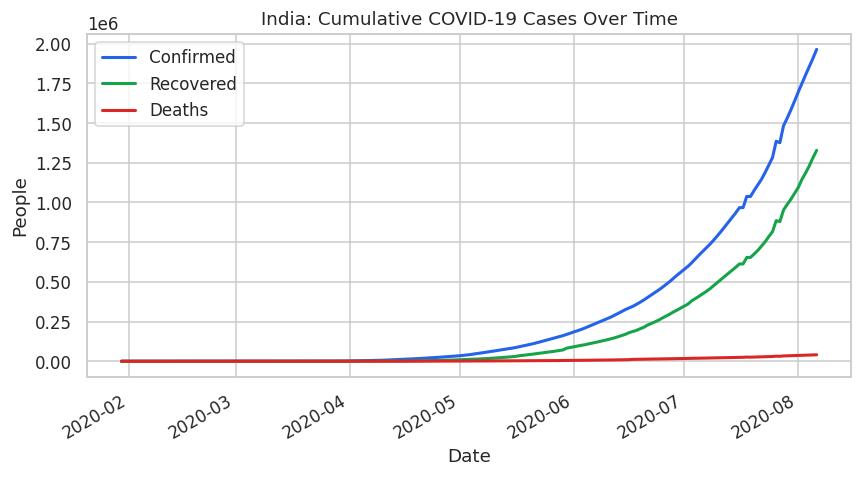

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national["date"], national["confirmed"], label="Confirmed", color="#2563eb", lw=2)
ax.plot(national["date"], national["cured"], label="Recovered", color="#16a34a", lw=2)
ax.plot(national["date"], national["deaths"], label="Deaths", color="#dc2626", lw=2)
ax.set_title("India: Cumulative COVID-19 Cases Over Time")
ax.set_xlabel("Date"); ax.set_ylabel("People")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

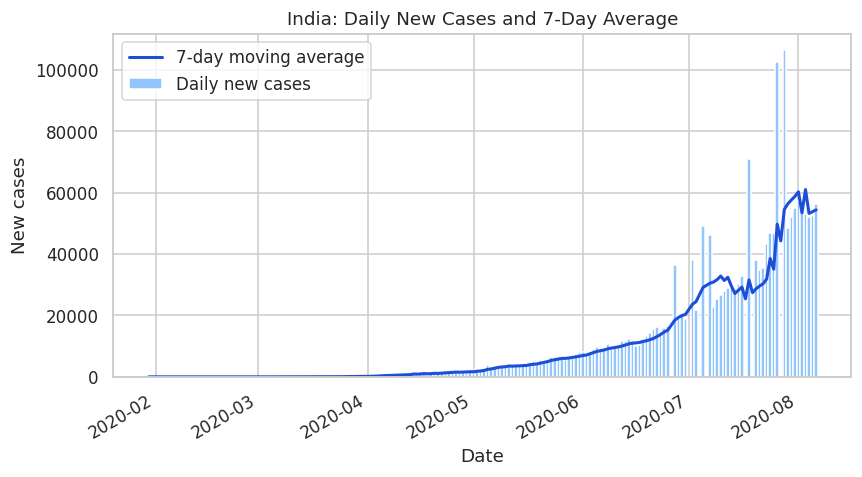

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(national["date"], national["new_confirmed"], color="#93c5fd", width=1.0, label="Daily new cases")
ax.plot(national["date"], national["new_cases_7day_avg"], color="#1d4ed8", lw=2,
        label="7-day moving average")
ax.set_title("India: Daily New Cases and 7-Day Average")
ax.set_xlabel("Date"); ax.set_ylabel("New cases")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


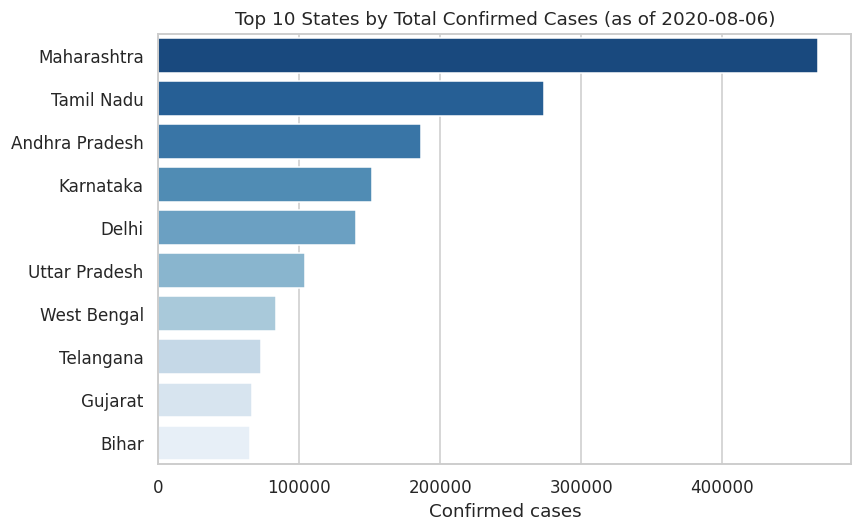

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top10, y="state", x="confirmed", hue="state", palette="Blues_r", legend=False, ax=ax)
ax.set_title(f"Top 10 States by Total Confirmed Cases (as of {latest_date.date()})")
ax.set_xlabel("Confirmed cases"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

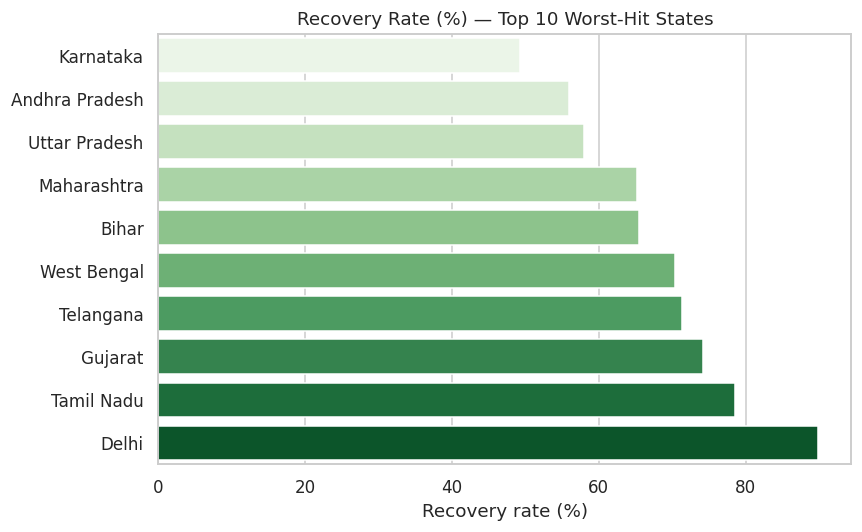

In [17]:
top10_sorted = top10.sort_values("recovery_rate")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top10_sorted, y="state", x="recovery_rate", hue="state", palette="Greens", legend=False, ax=ax)
ax.set_title("Recovery Rate (%) — Top 10 Worst-Hit States")
ax.set_xlabel("Recovery rate (%)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

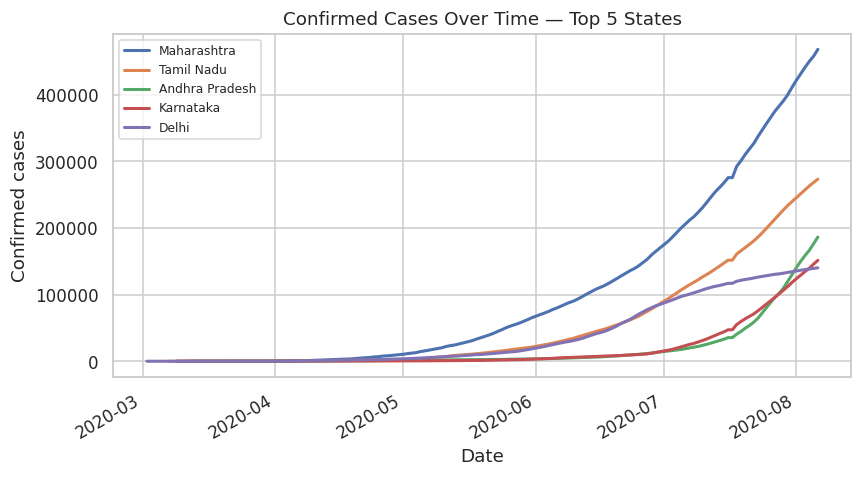

In [18]:
top5_states = top10["state"].head(5).tolist()

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in top5_states:
    sub = cases[cases["state"] == s]
    ax.plot(sub["date"], sub["confirmed"], label=s, lw=2)
ax.set_title("Confirmed Cases Over Time — Top 5 States")
ax.set_xlabel("Date"); ax.set_ylabel("Confirmed cases")
ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

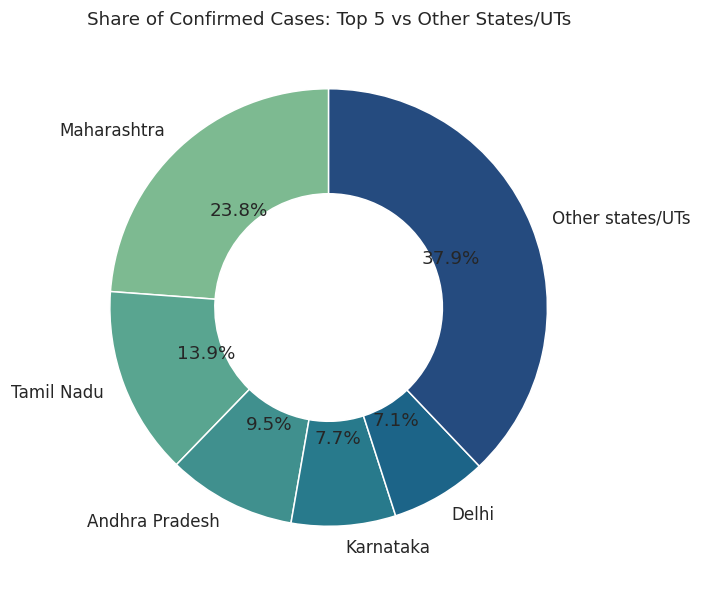

In [19]:
top5_share = latest.nlargest(5, "confirmed")[["state", "confirmed"]]
rest_cases = latest["confirmed"].sum() - top5_share["confirmed"].sum()
pie_labels = top5_share["state"].tolist() + ["Other states/UTs"]
pie_values = top5_share["confirmed"].tolist() + [rest_cases]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(pie_values, labels=pie_labels, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("crest", 6), wedgeprops={"width": 0.48})
ax.set_title("Share of Confirmed Cases: Top 5 vs Other States/UTs")
plt.tight_layout()
plt.show()


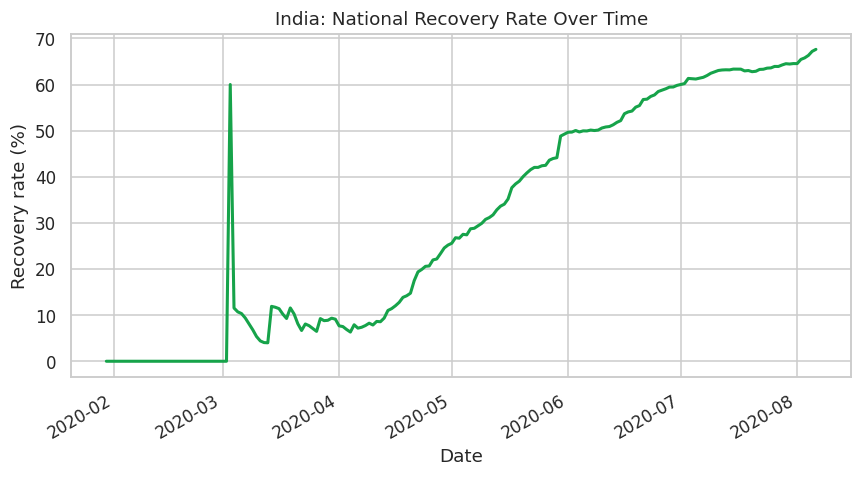

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national["date"], national["recovery_rate"], color="#16a34a", lw=2)
ax.set_title("India: National Recovery Rate Over Time")
ax.set_xlabel("Date"); ax.set_ylabel("Recovery rate (%)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

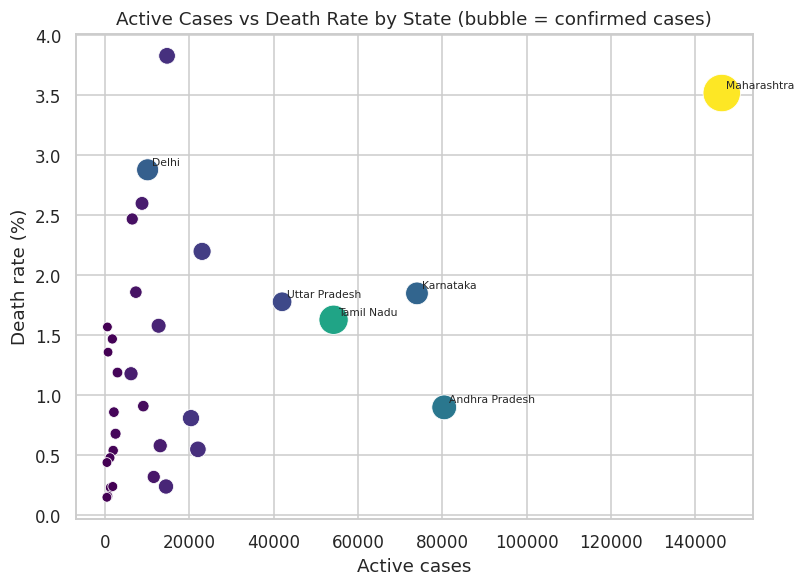

In [21]:
sizeable = latest[latest["confirmed"] >= 1000].copy()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=sizeable, x="active", y="death_rate", size="confirmed",
                sizes=(40, 600), hue="confirmed", palette="viridis", legend=False, ax=ax)
for _, r in sizeable.nlargest(6, "confirmed").iterrows():
    ax.annotate(r["state"], (r["active"], r["death_rate"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_title("Active Cases vs Death Rate by State (bubble = confirmed cases)")
ax.set_xlabel("Active cases"); ax.set_ylabel("Death rate (%)")
plt.tight_layout()
plt.show()


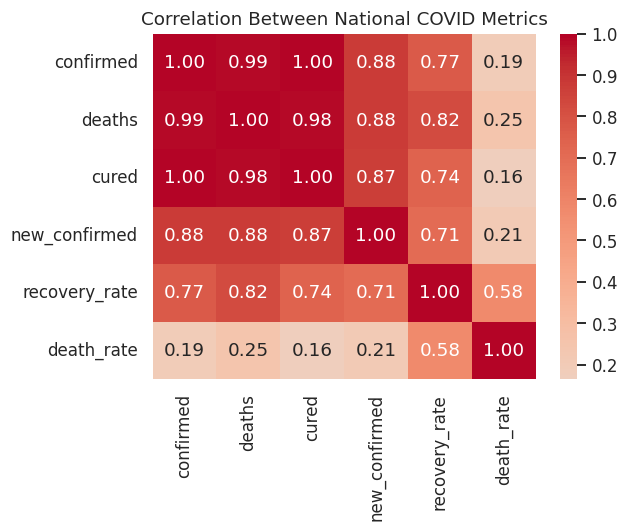

In [22]:
corr_cols = ["confirmed", "deaths", "cured", "new_confirmed", "recovery_rate", "death_rate"]
corr = national[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between National COVID Metrics")
plt.tight_layout()
plt.show()

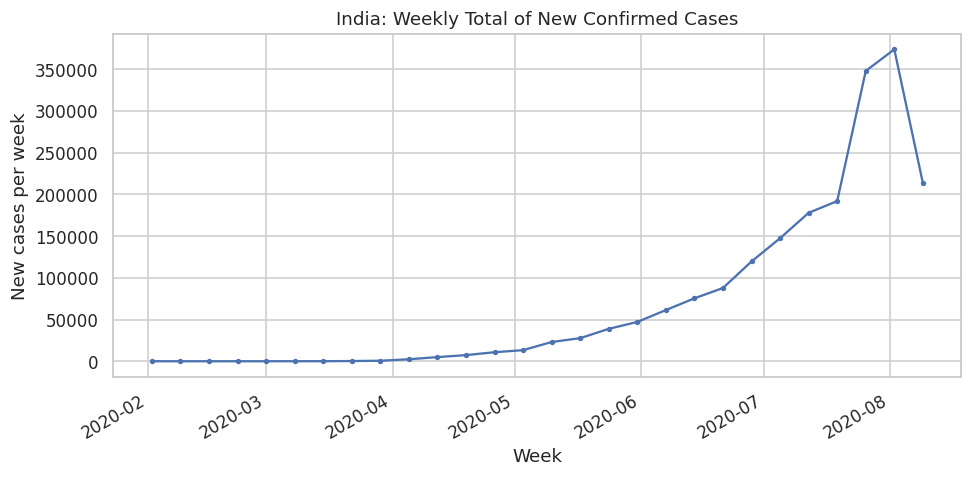

In [23]:
# Aggregate daily new cases into calendar weeks
weekly = national.set_index("date")["new_confirmed"].resample("W").sum().reset_index()
weekly["week_start"] = weekly["date"].dt.strftime("%d %b %Y")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(weekly["date"], weekly["new_confirmed"], marker="o", markersize=2.5, lw=1.5)
ax.set_title("India: Weekly Total of New Confirmed Cases")
ax.set_xlabel("Week"); ax.set_ylabel("New cases per week")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


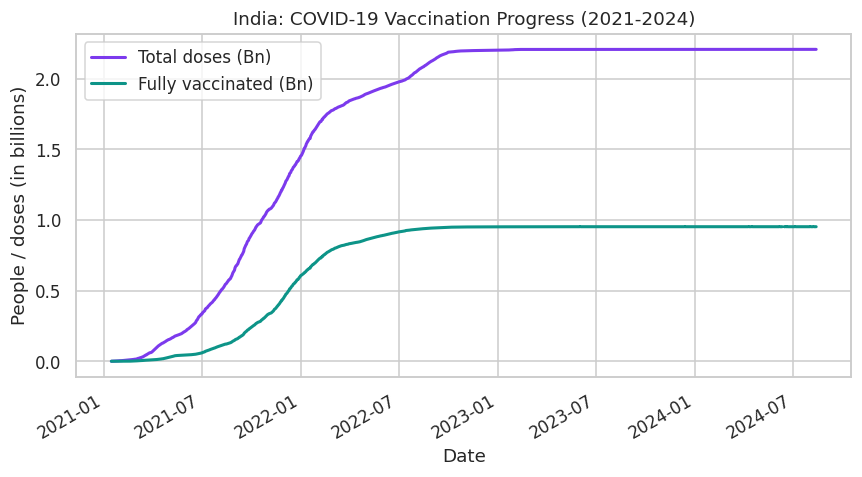

In [24]:
vax["date"] = pd.to_datetime(vax["date"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(vax["date"], vax["total_vaccinations"] / 1e9, label="Total doses (Bn)", color="#7c3aed", lw=2)
ax.plot(vax["date"], vax["people_fully_vaccinated"] / 1e9, label="Fully vaccinated (Bn)", color="#0d9488", lw=2)
ax.set_title("India: COVID-19 Vaccination Progress (2021-2024)")
ax.set_xlabel("Date"); ax.set_ylabel("People / doses (in billions)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

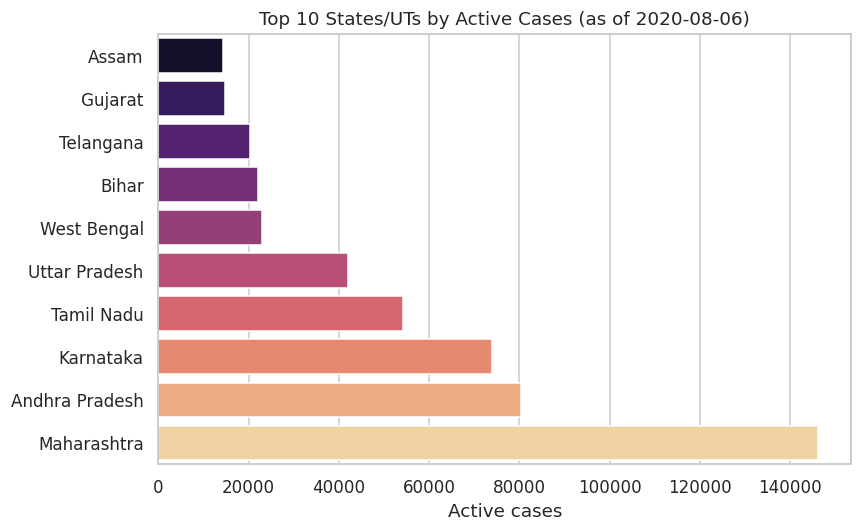

In [25]:
top_active = latest.nlargest(10, "active").sort_values("active", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top_active, y="state", x="active", hue="state", palette="magma", legend=False, ax=ax)
ax.set_title(f"Top 10 States/UTs by Active Cases (as of {latest_date.date()})")
ax.set_xlabel("Active cases"); ax.set_ylabel("")
plt.tight_layout()
plt.show()


In [26]:
cases.to_csv("modified_cleaned_covid_india.csv", index=False)
print("Saved modified_cleaned_covid_india.csv —", cases.shape[0], "rows and", cases.shape[1], "columns.")


Saved modified_cleaned_covid_india.csv — 4691 rows and 12 columns.


In [27]:
last = national.iloc[-1]
peak_idx = national["new_confirmed"].idxmax()
peak_row = national.loc[peak_idx]
top_states_text = ", ".join(latest.nlargest(5, "confirmed")["state"].astype(str).tolist())

print("COVID-19 EDA SUMMARY")
print("=" * 50)
print(f"Coverage: {cases['date'].min():%d %B %Y} to {cases['date'].max():%d %B %Y}; {cases['state'].nunique()} state/UT names after cleaning.")
print(f"Latest totals ({latest_date:%d %B %Y}): {int(last['confirmed']):,} confirmed, {int(last['cured']):,} recovered, {int(last['deaths']):,} deaths, and {int(last['active']):,} active cases.")
print(f"Recovery rate: {last['recovery_rate']:.2f}% | Death rate: {last['death_rate']:.2f}%")
print(f"Highest daily increase: {int(peak_row['new_confirmed']):,} cases on {peak_row['date']:%d %B %Y}.")
print(f"Top five states/UTs by confirmed cases: {top_states_text}.")
print("Note: Case and vaccination data cover different periods; rates are simple descriptive ratios.")


COVID-19 EDA SUMMARY
Coverage: 30 January 2020 to 06 August 2020; 35 state/UT names after cleaning.
Latest totals (06 August 2020): 1,964,536 confirmed, 1,328,336 recovered, 40,699 deaths, and 595,501 active cases.
Recovery rate: 67.62% | Death rate: 2.07%
Highest daily increase: 106,421 cases on 28 July 2020.
Top five states/UTs by confirmed cases: Maharashtra, Tamil Nadu, Andhra Pradesh, Karnataka, Delhi.
Note: Case and vaccination data cover different periods; rates are simple descriptive ratios.
